# Altair vs Aconcagua: cross-screen reproducibility at the gene level
For Louise. Two independent optical pooled CRISPR screens of A549 cells:
- **Altair** (Liu, Leonetti et al.): 1,000-gene KO, label-free **phase** morphology (via Tim Treis's [`prep-ops`](https://github.com/timtreis/cytodata-hackathon-prep-ops) `phase_guide.h5ad`).
- **Aconcagua** (Funk / Brieflow, doi:10.1101/2025.05.26.656231): essential-gene screen, 4-channel **fluorescence** (DAPI, γH2AX, PHALLOIDIN, TUBULIN), 31M cells in `s3://ops-explorer-public/aconcagua/aconcagua/cell_data.parquet`.

**Two things this notebook gives you:**
1. The **guide/gene-level Aconcagua table** you wanted (there is no prebuilt one; it is a `groupby` on the 323 GB cell table, since every cell carries its guide `barcode` and `perturbation_id`). Full DuckDB recipe for the VM, plus a small sampled demo that runs offline.
2. A **cross-screen comparison**: do two independent screens recover the same gene-function structure, and which gene relationships reproduce.

**Demo result (lean: 4 row groups, 108 features): significant but modest** cross-screen gene-gene structure (Spearman rho approx 0.10, z approx 48 vs a shuffled null; 10-NN overlap approx 3.4x chance) over the shared genes. Treat this as a lower bound; the full-feature, full-cell run on the VM should be stronger.

In [1]:
import os, warnings
from pathlib import Path
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
rng=np.random.default_rng(0); DATA=Path("data"); FIG=Path("figures/cross_screen"); FIG.mkdir(parents=True,exist_ok=True)

## 1. Aconcagua to gene level

**Full run (do this on the hackathon VM, where S3 egress is free).** DuckDB groups the 31M-cell table by gene over all 1,607 features, with the mapping-QC filter:
```python
import duckdb
url="https://ops-explorer-public.s3.us-west-2.amazonaws.com/aconcagua/aconcagua/cell_data.parquet"
con=duckdb.connect(); con.sql("INSTALL httpfs; LOAD httpfs;")
acon_gene = con.sql(f'''
    SELECT perturbation_id AS gene, count(*) AS n_cells,
           avg(COLUMNS('^(cell|cytoplasm|nucleus)_.*'))
    FROM read_parquet('{url}')
    WHERE mapped_single_gene AND perturbation_id NOT LIKE 'nontargeting%'
    GROUP BY perturbation_id
''').df()
```
For guide level instead, `GROUP BY barcode` and keep `perturbation_id` with `any_value`.

**Offline demo** (what runs below): a sample of a few row groups with a lean feature subset, cached to `data/aconcagua_gene_demo.parquet`.

In [2]:
demo=DATA/"aconcagua_gene_demo.parquet"
if demo.exists():
    ag=pd.read_parquet(demo); print("loaded cached Aconcagua demo gene table")
else:
    import s3fs, pyarrow.parquet as pq
    fs=s3fs.S3FileSystem(anon=True)
    pf=pq.ParquetFile(fs.open("ops-explorer-public/aconcagua/aconcagua/cell_data.parquet","rb"))
    feat=[c for c in pf.schema.names if c.startswith(("cell_DAPI_pftas","cell_TUBULIN_pftas"))]
    fr=[pf.read_row_group(i,columns=["perturbation_id","mapped_single_gene"]+feat).to_pandas() for i in range(4)]
    d=pd.concat(fr); d=d[d.mapped_single_gene==True]; d["gene"]=d.perturbation_id.astype(str)
    d=d[~d.gene.str.startswith("nontargeting")]
    ag=d.groupby("gene")[feat].mean(); ag=ag[d.groupby("gene").size()>=20]; ag.to_parquet(demo)
print("Aconcagua gene table:", ag.shape, "(genes x features)")

loaded cached Aconcagua demo gene table
Aconcagua gene table: (5019, 108) (genes x features)


## 2. Altair to gene level (Tim's phase profiles)

In [3]:
ph=ad.read_h5ad(DATA/"phase_guide.h5ad"); ph=ph[:,ph.var["selected"].values].copy()
ph.X=np.clip(np.nan_to_num(ph.X),-50,50)
dfa=pd.DataFrame(ph.X,index=ph.obs["target_gene"].astype(str)); dfa=dfa[dfa.index!="NTC"]
alt=dfa.groupby(level=0).mean()
print("Altair phase gene table:", alt.shape, "(genes x features)")

Altair phase gene table: (1000, 337) (genes x features)


## 3. Cross-screen gene-gene structure
Each screen embeds genes in its own feature space (different modalities, so we compare *relationships*, not raw features). Within each screen we z-score features and compute every gene-gene cosine similarity, then correlate the two similarity matrices over shared genes (Spearman, Mantel style) against a shuffled null, and measure 10-nearest-neighbour overlap.

shared genes: 793


Spearman rho(Altair phase vs Aconcagua fluor) = 0.096 | null +0.000+/-0.002 | z=48
10-NN overlap = 0.043 (chance 0.0126, i.e. 3.4x)


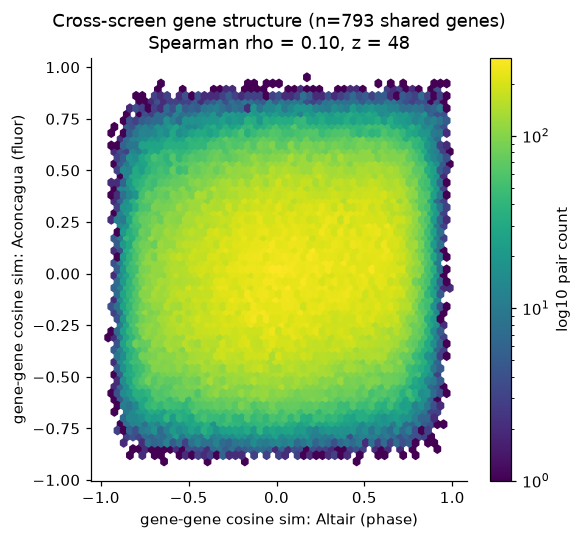

In [4]:
shared=sorted(set(ag.index)&set(alt.index)); print("shared genes:",len(shared))
A=StandardScaler().fit_transform(alt.loc[shared].values); C=StandardScaler().fit_transform(ag.loc[shared].values)
Sa,Sc=cosine_similarity(A),cosine_similarity(C); iu=np.triu_indices(len(shared),1)
rho=spearmanr(Sa[iu],Sc[iu]).statistic
null=np.array([spearmanr(Sa[iu],Sc[np.ix_(p,p)][iu]).statistic for p in (rng.permutation(len(shared)) for _ in range(200))])
z=(rho-null.mean())/null.std()
def knn(S,k=10): return [set(np.argsort(-S[i])[1:k+1]) for i in range(len(S))]
na,nc=knn(Sa),knn(Sc); ov=np.mean([len(na[i]&nc[i])/10 for i in range(len(shared))])
print(f"Spearman rho(Altair phase vs Aconcagua fluor) = {rho:.3f} | null {null.mean():+.3f}+/-{null.std():.3f} | z={z:.0f}")
print(f"10-NN overlap = {ov:.3f} (chance {10/len(shared):.4f}, i.e. {ov/(10/len(shared)):.1f}x)")
fig,ax=plt.subplots(figsize=(5.4,5))
hb=ax.hexbin(Sa[iu],Sc[iu],gridsize=55,bins="log",cmap="viridis",mincnt=1)
ax.set_xlabel("gene-gene cosine sim: Altair (phase)"); ax.set_ylabel("gene-gene cosine sim: Aconcagua (fluor)")
ax.set_title(f"Cross-screen gene structure (n={len(shared)} shared genes)\nSpearman rho = {rho:.2f}, z = {z:.0f}")
fig.colorbar(hb,label="log10 pair count"); plt.tight_layout(); plt.savefig(FIG/"cross_screen_structure.png",bbox_inches="tight",dpi=150); plt.show()

## 4. Which gene relationships reproduce across screens

In [5]:
ex=[g for g in ["RPS6","RPL13","TUBB","ACTB","CCT2","POLR2A","PSMB5"] if g in shared][:5]
pos={g:i for i,g in enumerate(shared)}
for g in ex:
    i=pos[g]
    na5=set(np.argsort(-Sa[i])[1:6]); nc5=set(np.argsort(-Sc[i])[1:6])
    both=[shared[j] for j in (na5&nc5)]
    print(f"{g}: shared top-5 neighbours across both screens -> {both if both else '(none in top-5)'}")

## 5. Takeaways and how to run it full

- **The guide/gene-level Aconcagua table is a `groupby`, not a missing file** (every cell carries its guide `barcode` and gene `perturbation_id`). Use the DuckDB recipe in section 1 on the VM for the full 31M-cell, 1,607-feature aggregation.
- **Two independent A549 OPS screens share real gene-function structure** (significant vs a shuffled null) even across different imaging modalities (label-free phase vs 4-channel fluorescence). In this lean demo the effect is modest (rho approx 0.10); expect it to strengthen with the full feature set and all cells, and when comparing matched feature families (for example tubulin and actin in both).
- This gives a reproducibility baseline and a shared-gene set to carry into the Altair cross-modal work.

**Caveats:** demo uses 4 of 254 row groups and only cell DAPI and TUBULIN pftas features; different screens, preps and libraries; the comparison is relationship-based because the two feature spaces are not identical.